<a href="https://colab.research.google.com/github/tqan27/DiscreteAssignment/blob/main/Q4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Q4

a) Data Loading and Processing

In [ ]:
import pandas as pd

# Load the CSV files
file1_path = 'hh_income_state.csv'
file2_path = 'data_kaggle.csv'

# Read the CSV files into DataFrames
df1 = pd.read_csv(file1_path)
df2 = pd.read_csv(file2_path)

# Identify missing values
print("Missing values in hh_income_state.csv:")
print(df1.isnull().sum())

print("\nMissing values in data_kaggle.csv:")
print(df2.isnull().sum())

# Handle missing values in hh_income_state.csv
# Fill missing values in 'income_median' with the median of the column
df1['income_median'] = df1['income_median'].fillna(df1['income_median'].median())

# Handle missing values in data_kaggle.csv
# Fill missing 'Price' and 'Rooms' with "unknown"
df2['Price'] = df2['Price'].fillna("unknown")
df2['Rooms'] = df2['Rooms'].fillna("unknown")

# Fill missing 'Bathrooms' with the mean value
df2['Bathrooms'] = df2['Bathrooms'].fillna(df2['Bathrooms'].mean())

# Fill missing 'Car Parks' with the median value
df2['Car Parks'] = df2['Car Parks'].fillna(df2['Car Parks'].median())

# For any other missing values, fill with "unknown"
df2 = df2.fillna("unknown")

# Display the cleaned DataFrames
print("\nCleaned hh_income_state.csv:")
print(df1.head())

print("\nCleaned data_kaggle.csv:")
print(df2.head())

# Save the cleaned DataFrames to new CSV files
df1.to_csv('cleaned_hh_income_state.csv', index=False)
df2.to_csv('cleaned_data_kaggle.csv', index=False)

print("\nCleaned files have been saved as 'cleaned_hh_income_state.csv' and 'cleaned_data_kaggle.csv'.")


Missing values in hh_income_state.csv:
state             0
date              0
income_mean       0
income_median    11
dtype: int64

Missing values in data_kaggle.csv:
Location             0
Price              248
Rooms             1706
Bathrooms         2013
Car Parks        17567
Property Type       25
Size              1063
Furnishing        6930
dtype: int64

Cleaned hh_income_state.csv:
   state        date  income_mean  income_median
0  Johor  1970-01-01          237         1794.5
1  Johor  1974-01-01          382          269.0
2  Johor  1976-01-01          513          370.0
3  Johor  1979-01-01          731          518.0
4  Johor  1984-01-01         1065          793.0

Cleaned data_kaggle.csv:
                          Location         Price    Rooms  Bathrooms  \
0               KLCC, Kuala Lumpur  RM 1,250,000      2+1   3.000000   
1  Damansara Heights, Kuala Lumpur  RM 6,800,000        6   7.000000   
2            Dutamas, Kuala Lumpur  RM 1,030,000        3   4.000000 

b) Exploratory data analysis to understand the distribution of the data and relationships between features


General Information for hh_income_state.csv:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   state          303 non-null    object 
 1   date           303 non-null    object 
 2   income_mean    303 non-null    int64  
 3   income_median  303 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 9.6+ KB
None

Statistical Summary of hh_income_state.csv:
        income_mean  income_median
count    303.000000     303.000000
mean    3342.069307    2582.866337
std     2887.644730    2218.674433
min      140.000000     108.000000
25%     1062.500000     837.500000
50%     2429.000000    1794.500000
75%     5011.500000    3820.000000
max    13473.000000   10549.000000


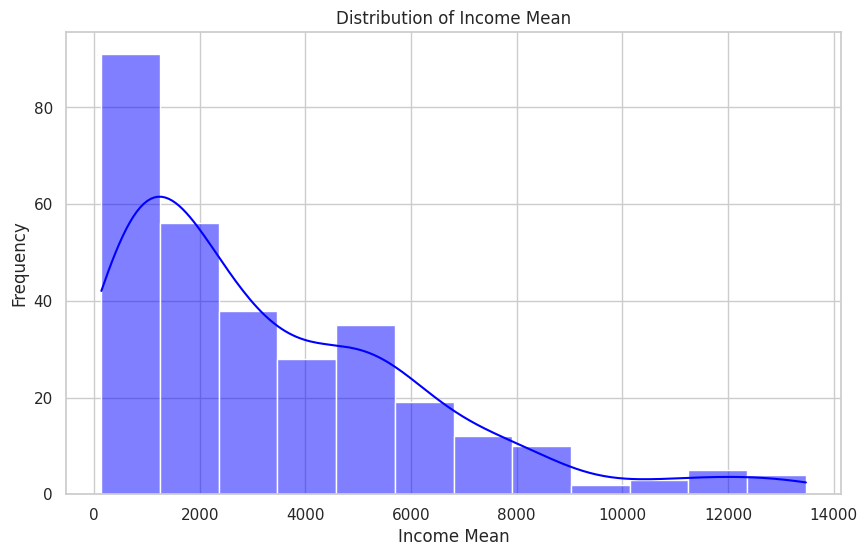

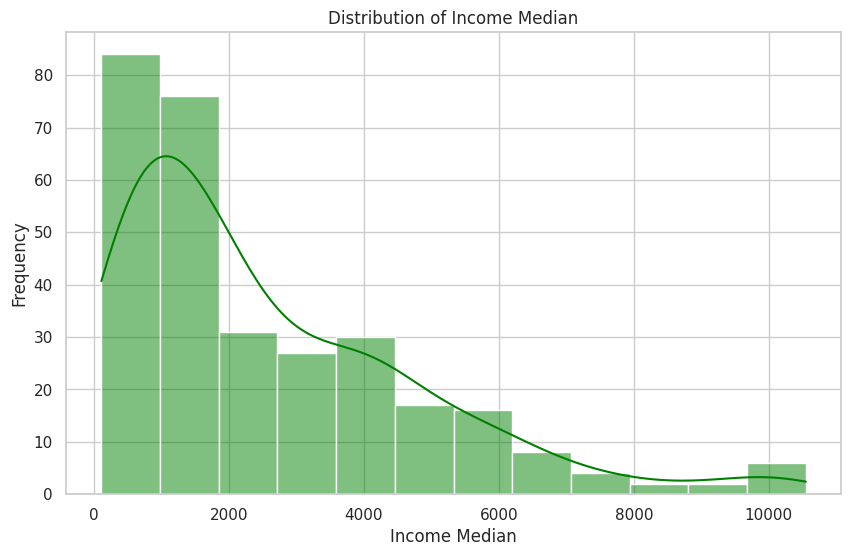

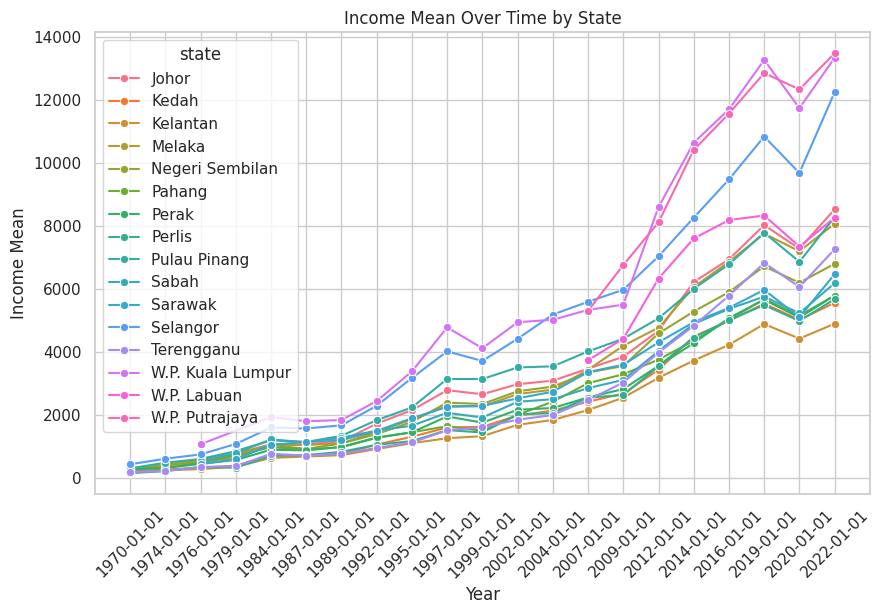

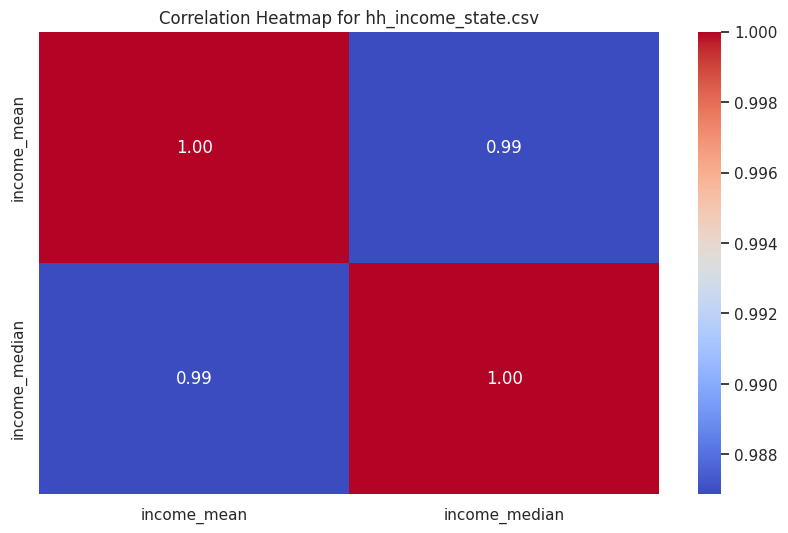


General Information for data_kaggle.csv:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53883 entries, 0 to 53882
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Location       53883 non-null  object 
 1   Price          53883 non-null  object 
 2   Rooms          53883 non-null  object 
 3   Bathrooms      53883 non-null  float64
 4   Car Parks      53883 non-null  float64
 5   Property Type  53883 non-null  object 
 6   Size           53883 non-null  object 
 7   Furnishing     53883 non-null  object 
dtypes: float64(2), object(6)
memory usage: 3.3+ MB
None

Statistical Summary of data_kaggle.csv:
                        Location         Price  Rooms     Bathrooms  \
count                      53883         53883  53883  53883.000000   
unique                       112          4281     44           NaN   
top     Mont Kiara, Kuala Lumpur  RM 1,200,000      3           NaN   
freq                        

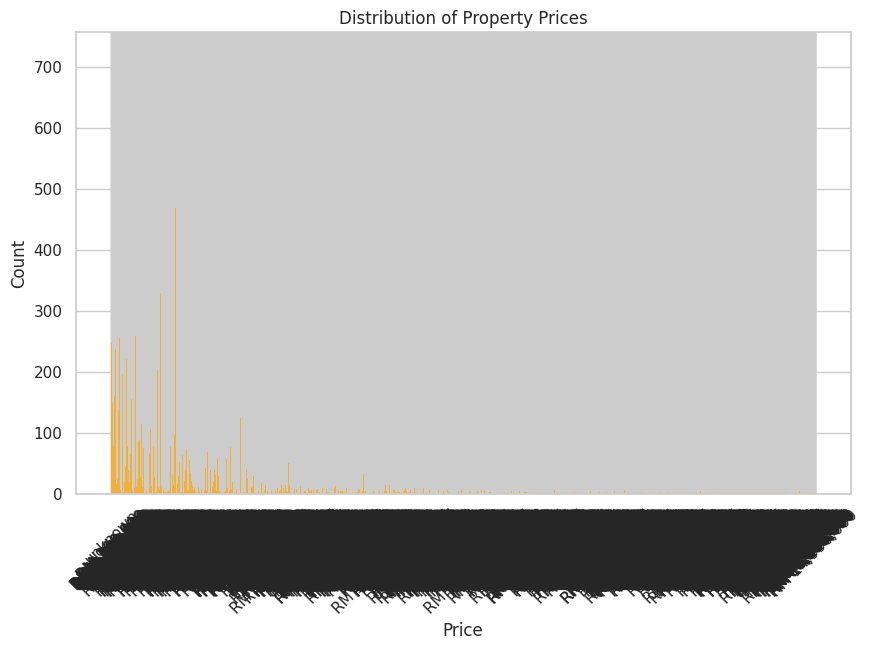

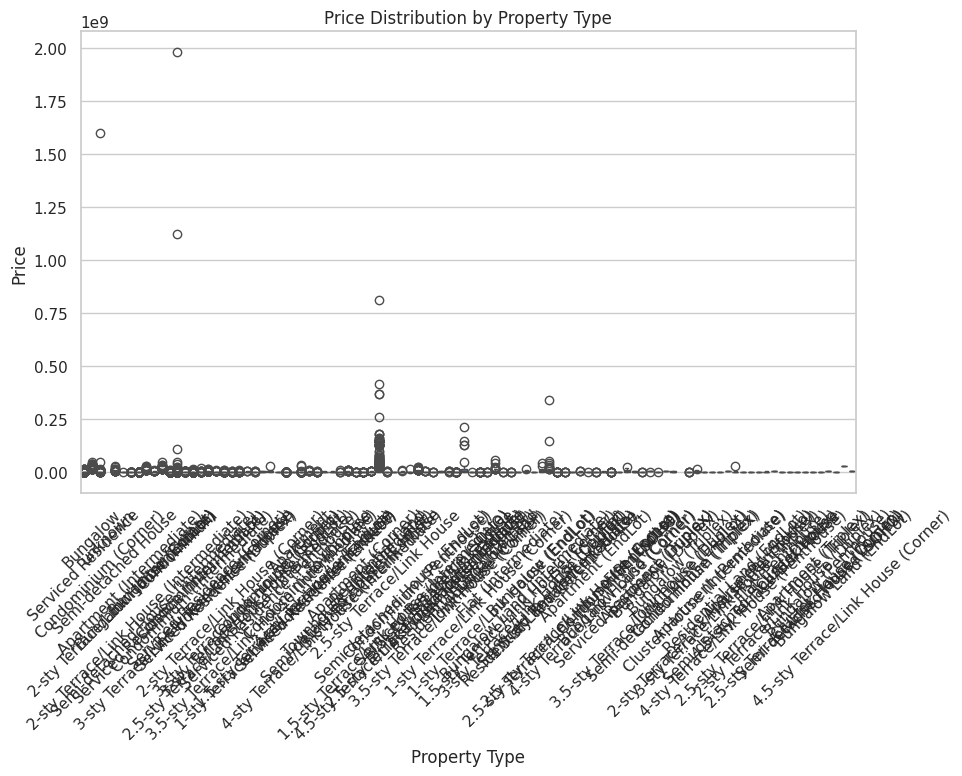


EDA Complete. Cleaned files saved for future use.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned CSV files
df1 = pd.read_csv('cleaned_hh_income_state.csv')
df2 = pd.read_csv('cleaned_data_kaggle.csv')

# General Settings for Visualization
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# ----------------------------
# EDA for hh_income_state.csv
# ----------------------------
print("\nGeneral Information for hh_income_state.csv:")
print(df1.info())

print("\nStatistical Summary of hh_income_state.csv:")
print(df1.describe())

# Distribution of income_mean
plt.figure()
sns.histplot(df1['income_mean'], kde=True, color='blue')
plt.title('Distribution of Income Mean')
plt.xlabel('Income Mean')
plt.ylabel('Frequency')
plt.show()

# Distribution of income_median
plt.figure()
sns.histplot(df1['income_median'], kde=True, color='green')
plt.title('Distribution of Income Median')
plt.xlabel('Income Median')
plt.ylabel('Frequency')
plt.show()

# Income trends over time
plt.figure()
sns.lineplot(data=df1, x='date', y='income_mean', hue='state', marker='o')
plt.title('Income Mean Over Time by State')
plt.xlabel('Year')
plt.ylabel('Income Mean')
plt.xticks(rotation=45)
plt.show()

# Select only numeric columns for correlation
numeric_columns = df1.select_dtypes(include=['float64', 'int64'])

# Compute correlation matrix
correlation_matrix = numeric_columns.corr()

# Plot the heatmap
plt.figure()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap for hh_income_state.csv')
plt.show()

# ----------------------------
# EDA for data_kaggle.csv
# ----------------------------
print("\nGeneral Information for data_kaggle.csv:")
print(df2.info())

print("\nStatistical Summary of data_kaggle.csv:")
print(df2.describe(include='all'))

df2['Price_clean'] = pd.to_numeric(df2['Price'].str.replace('[^\d.]', '', regex=True), errors='coerce')

# Distribution of Prices
plt.figure()
sns.histplot(df2['Price'], kde=False, color='orange', bins=20)
plt.title('Distribution of Property Prices')
plt.xlabel('Price')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

# Boxplot: Price by Property Type
plt.figure()
sns.boxplot(data=df2, x='Property Type', y='Price_clean')
plt.title('Price Distribution by Property Type')
plt.xlabel('Property Type')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.show()

# ----------------------------
# Save Cleaned Data for Future Use
# ----------------------------
df1.to_csv('final_cleaned_hh_income_state.csv', index=False)
df2.to_csv('final_cleaned_data_kaggle.csv', index=False)

print("\nEDA Complete. Cleaned files saved for future use.")


C)Model building

Build a decision tree classifier to predict the type of house a worker can afford.

Training housing affordability model...

Model Performance:


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                                                    precision    recall  f1-score   support

Affordable 2-sty Terrace/Link House (Intermediate)       0.00      0.00      0.00         1
Affordable 3-sty Terrace/Link House (Intermediate)       0.00      0.00      0.00         1
                              Affordable Apartment       0.00      0.00      0.00         5
               Affordable Apartment (Intermediate)       0.00      0.00      0.00         1
                               Affordable Bungalow       0.00      0.00      0.00         1
                          Affordable Bungalow Land       0.00      0.00      0.00         1
                            Affordable Condominium       1.00      1.00      1.00        25
                   Affordable Condominium (Corner)       1.00      1.00      1.00         6
             Affordable Condominium (Intermediate)       0.00      0.00      0.00         7
                                   Affordable Flat       0.00      0.00      0.

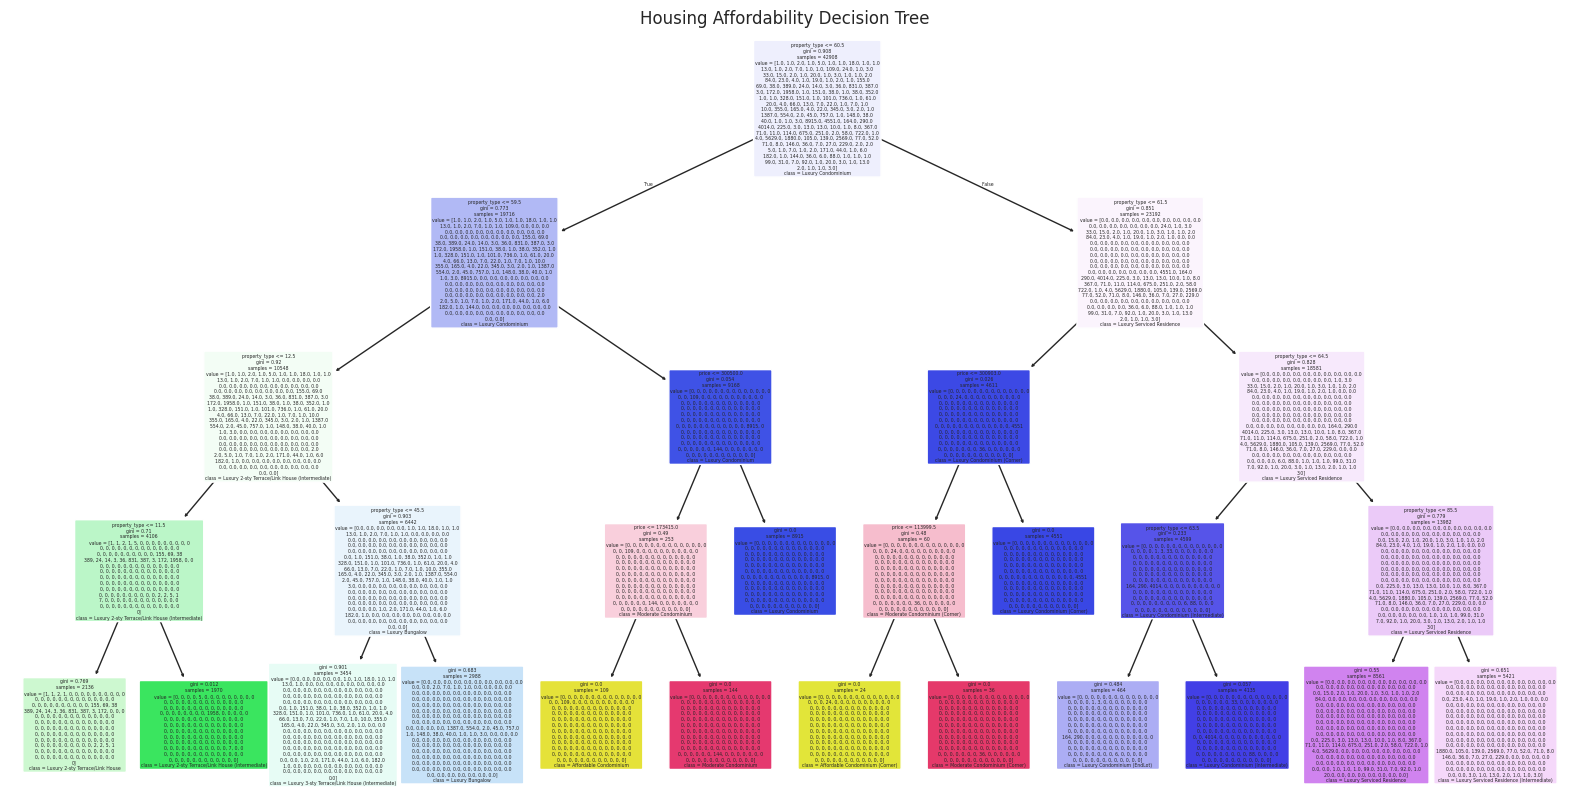


Example Predictions:
--------------------------------------------------
Income: $50,000, Property Type: House
Recommended Category: Luxury 2-sty Terrace/Link House

Income: $50,000, Property Type: Apartment
Recommended Category: Luxury 2-sty Terrace/Link House

Income: $50,000, Property Type: Townhouse
Recommended Category: Luxury 2-sty Terrace/Link House

Income: $100,000, Property Type: House
Recommended Category: Luxury 2-sty Terrace/Link House

Income: $100,000, Property Type: Apartment
Recommended Category: Luxury 2-sty Terrace/Link House

Income: $100,000, Property Type: Townhouse
Recommended Category: Luxury 2-sty Terrace/Link House

Income: $150,000, Property Type: House
Recommended Category: Luxury 2-sty Terrace/Link House

Income: $150,000, Property Type: Apartment
Recommended Category: Luxury 2-sty Terrace/Link House

Income: $150,000, Property Type: Townhouse
Recommended Category: Luxury 2-sty Terrace/Link House



/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local

In [ ]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

def prepare_data(income_file='final_cleaned_hh_income_state.csv',
                housing_file='final_cleaned_data_kaggle.csv'):
    # Load datasets
    income_df = pd.read_csv(income_file)
    housing_df = pd.read_csv(housing_file)

    # Clean price data
    housing_df['Price_clean'] = pd.to_numeric(housing_df['Price'].str.replace('[^\d.]', '', regex=True),
                                            errors='coerce')

    # Calculate affordability threshold (using 3x annual income as a rule of thumb)
    income_levels = income_df['income_median'].unique()

    # Create affordability categories
    def categorize_house(price, property_type):
        if pd.isna(price):
            return "Unknown"
        elif price <= 150000:
            return f"Affordable {property_type}"
        elif price <= 300000:
            return f"Moderate {property_type}"
        else:
            return f"Luxury {property_type}"

    # Create target variable
    housing_df['house_category'] = housing_df.apply(
        lambda x: categorize_house(x['Price_clean'], x['Property Type']), axis=1
    )

    # Prepare features
    features_df = pd.DataFrame({
        'price': housing_df['Price_clean'],
        'property_type': LabelEncoder().fit_transform(housing_df['Property Type'])
    })

    combined_df = pd.concat([features_df, housing_df['house_category']], axis=1)
    combined_df = combined_df.dropna()  # Now drop NaNs from the combined DataFrame

    return combined_df[['price', 'property_type']], combined_df['house_category']

def train_predictor():
    # Prepare data
    X, y = prepare_data()

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Train model
    clf = DecisionTreeClassifier(max_depth=4, random_state=42)
    clf.fit(X_train, y_train)

    # Evaluate model
    print("\nModel Performance:")
    y_pred = clf.predict(X_test)
    print(classification_report(y_test, y_pred))

    # Visualize decision tree
    plt.figure(figsize=(20,10))
    plot_tree(clf, feature_names=['price', 'property_type'],
             class_names=clf.classes_, filled=True, rounded=True)
    plt.title("Housing Affordability Decision Tree")
    plt.show()

    return clf

def predict_housing(clf, income, desired_property_type):
    """
    Predict suitable housing category based on income and desired property type

    Parameters:
    income: Annual income
    desired_property_type: Type of property (House, Apartment, etc.)
    """
    # Convert property type to encoded value
    property_encoder = LabelEncoder()
    property_encoder.fit(['House', 'Apartment', 'Townhouse', 'Condo'])
    encoded_type = property_encoder.transform([desired_property_type])[0]

    # Calculate maximum affordable price (3x annual income)
    max_price = income * 3

    # Make prediction
    prediction = clf.predict([[max_price, encoded_type]])[0]

    return prediction

# Train the model and make example predictions
def main():
    # Train model
    print("Training housing affordability model...")
    clf = train_predictor()

    # Example predictions
    example_incomes = [50000, 100000, 150000]
    property_types = ['House', 'Apartment', 'Townhouse']

    print("\nExample Predictions:")
    print("-" * 50)
    for income in example_incomes:
        for prop_type in property_types:
            prediction = predict_housing(clf, income, prop_type)
            print(f"Income: RM{income:,}, Property Type: {prop_type}")
            print(f"Recommended Category: {prediction}\n")

if __name__ == "__main__":
    main()

Build a random forest classifier to predict the type of house a worker can afford


Model Performance:
              precision    recall  f1-score   support

 Entry Level       1.00      1.00      1.00        91
    High End       1.00      1.00      1.00      1693
      Luxury       1.00      1.00      1.00      8684
   Mid Range       1.00      1.00      1.00       259

    accuracy                           1.00     10727
   macro avg       1.00      1.00      1.00     10727
weighted avg       1.00      1.00      1.00     10727

Accuracy: 1.00


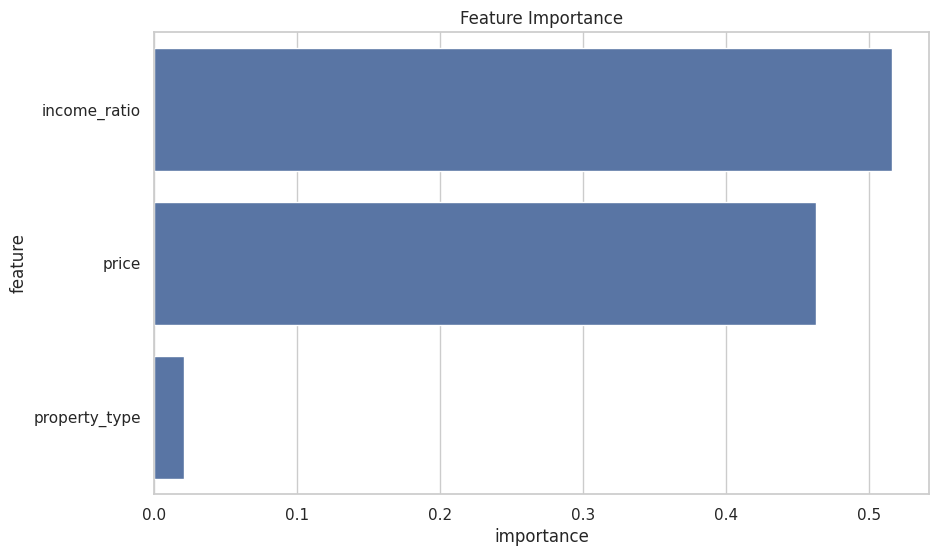


Example Predictions:
Error: Unknown property type: House

For income $50,000 looking for Apartment:
Recommended Category: Entry Level
Maximum Affordable Price: $150,000.00
Confidence: 90.76%

For income $50,000 looking for Townhouse:
Recommended Category: Entry Level
Maximum Affordable Price: $150,000.00
Confidence: 81.48%
Error: Unknown property type: House

For income $100,000 looking for Apartment:
Recommended Category: Mid Range
Maximum Affordable Price: $300,000.00
Confidence: 56.99%

For income $100,000 looking for Townhouse:
Recommended Category: Entry Level
Maximum Affordable Price: $300,000.00
Confidence: 54.48%
Error: Unknown property type: House

For income $150,000 looking for Apartment:
Recommended Category: High End
Maximum Affordable Price: $450,000.00
Confidence: 47.06%

For income $150,000 looking for Townhouse:
Recommended Category: High End
Maximum Affordable Price: $450,000.00
Confidence: 54.72%


/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ut

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

class HousingAffordabilityModel:
    def __init__(self):
        self.model = None
        self.property_encoder = LabelEncoder()
        self.scaler = StandardScaler()

    def load_and_prepare_data(self, income_file, housing_file):
        try:
            # Load datasets
            income_df = pd.read_csv(income_file)
            housing_df = pd.read_csv(housing_file)

            # Clean and process Price data
            housing_df['Price_clean'] = pd.to_numeric(
                housing_df['Price'].str.replace('[^\d.]', '', regex=True), errors='coerce'
            )
            housing_df = housing_df.dropna(subset=['Price_clean'])

            # Define price categories based on thresholds
            def categorize_house(price):
                if price <= 150000:
                    return "Entry Level"
                elif price <= 300000:
                    return "Mid Range"
                elif price <= 500000:
                    return "High End"
                else:
                    return "Luxury"

            housing_df['price_category'] = housing_df['Price_clean'].apply(categorize_house)

            # Encode property type
            housing_df['property_type_encoded'] = self.property_encoder.fit_transform(housing_df['Property Type'])

            # Median income for calculation
            median_income = income_df['income_median'].median()

            # Create feature matrix
            features = pd.DataFrame({
                'income_ratio': housing_df['Price_clean'] / median_income,
                'property_type': housing_df['property_type_encoded'],
                'price': housing_df['Price_clean']
            })

            # Standardize features
            features_scaled = self.scaler.fit_transform(features)

            # Target labels
            target = housing_df['price_category']

            return features_scaled, target, features.columns
        except Exception as e:
            print(f"Error loading and preparing data: {e}")
            raise

    def train_model(self, income_file, housing_file):
        try:
            # Prepare data
            X, y, feature_names = self.load_and_prepare_data(income_file, housing_file)

            # Split data
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

            # Train Random Forest model
            self.model = RandomForestClassifier(
                n_estimators=100,
                max_depth=5,
                random_state=42
            )
            self.model.fit(X_train, y_train)

            # Evaluate model
            y_pred = self.model.predict(X_test)
            print("\nModel Performance:")
            print(classification_report(y_test, y_pred))
            print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")

            # Feature importance
            self.plot_feature_importance(feature_names)

        except Exception as e:
            print(f"Error training model: {e}")
            raise

    def plot_feature_importance(self, feature_names):
        if self.model is None:
            raise ValueError("Model has not been trained yet.")

        importance = pd.DataFrame({
            'feature': feature_names,
            'importance': self.model.feature_importances_
        }).sort_values(by='importance', ascending=False)

        plt.figure(figsize=(10, 6))
        sns.barplot(data=importance, x='importance', y='feature')
        plt.title("Feature Importance")
        plt.show()

    def predict_housing_type(self, income, property_type):
        if self.model is None:
            raise ValueError("Model needs to be trained first.")

        if property_type not in self.property_encoder.classes_:
            raise ValueError(f"Unknown property type: {property_type}")

        # Encode property type
        property_type_encoded = self.property_encoder.transform([property_type])[0]

        # Median income for feature calculation
        median_income = income

        # Calculate features
        max_price = income * 3  # Example affordability rule
        income_ratio = max_price / median_income

        features = self.scaler.transform([[income_ratio, property_type_encoded, max_price]])

        # Predict
        prediction = self.model.predict(features)[0]
        proba = self.model.predict_proba(features)[0]

        return {
            'recommended_category': prediction,
            'confidence': max(proba),
            'max_affordable_price': max_price,
            'property_type': property_type
        }


# Main Function
def main():
    # Initialize model
    model = HousingAffordabilityModel()

    # Train model
    income_file = 'final_cleaned_hh_income_state.csv'
    housing_file = 'final_cleaned_data_kaggle.csv'
    model.train_model(income_file, housing_file)

    # Test prediction
    print("\nExample Predictions:")
    example_incomes = [50000, 100000, 150000]
    property_types = ['House', 'Apartment', 'Townhouse']

    for income in example_incomes:
        for prop_type in property_types:
            try:
                result = model.predict_housing_type(income, prop_type)
                print(f"\nFor income ${income:,} looking for {prop_type}:")
                print(f"Recommended Category: {result['recommended_category']}")
                print(f"Maximum Affordable Price: ${result['max_affordable_price']:,.2f}")
                print(f"Confidence: {result['confidence']:.2%}")
            except ValueError as e:
                print(f"Error: {e}")

if __name__ == "__main__":
    main()


D) Module evaluation with chart

Preparing data...

Training Decision Tree...

Decision Tree Performance:


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                                                    precision    recall  f1-score   support

Affordable 2-sty Terrace/Link House (Intermediate)       0.00      0.00      0.00         1
Affordable 3-sty Terrace/Link House (Intermediate)       0.00      0.00      0.00         1
                              Affordable Apartment       0.00      0.00      0.00         5
               Affordable Apartment (Intermediate)       0.00      0.00      0.00         1
                               Affordable Bungalow       0.00      0.00      0.00         1
                          Affordable Bungalow Land       0.00      0.00      0.00         1
                            Affordable Condominium       1.00      1.00      1.00        25
                   Affordable Condominium (Corner)       1.00      1.00      1.00         6
             Affordable Condominium (Intermediate)       0.00      0.00      0.00         7
                                   Affordable Flat       0.00      0.00      0.

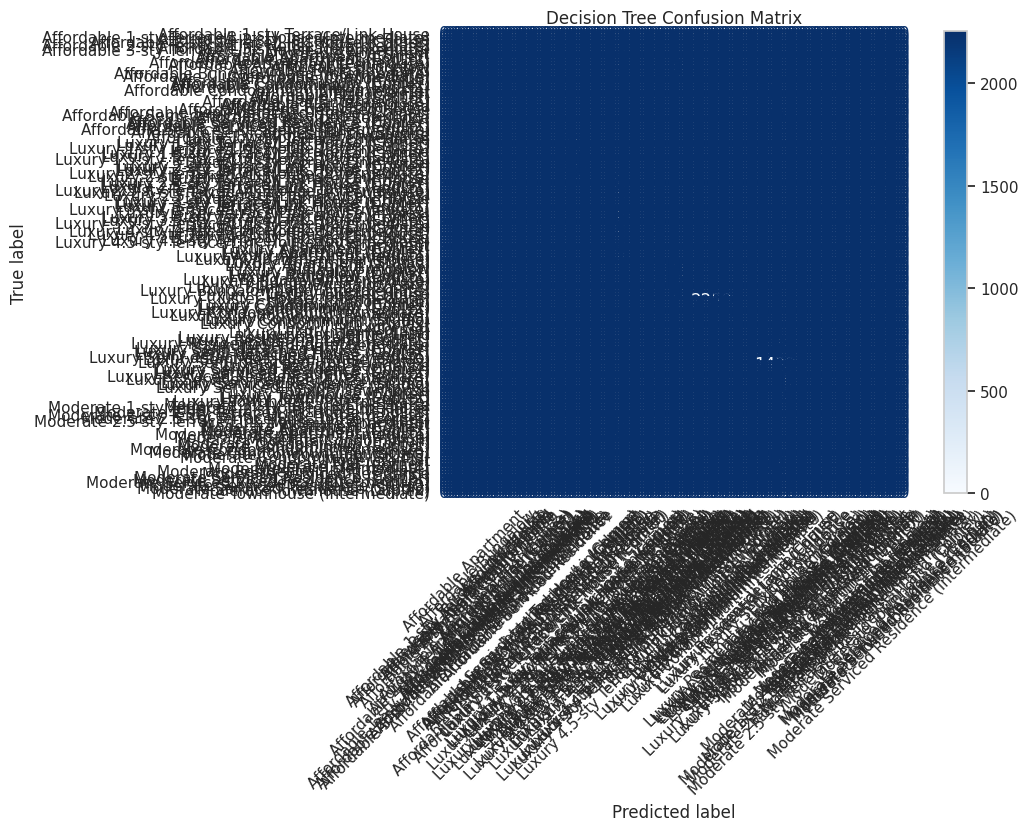

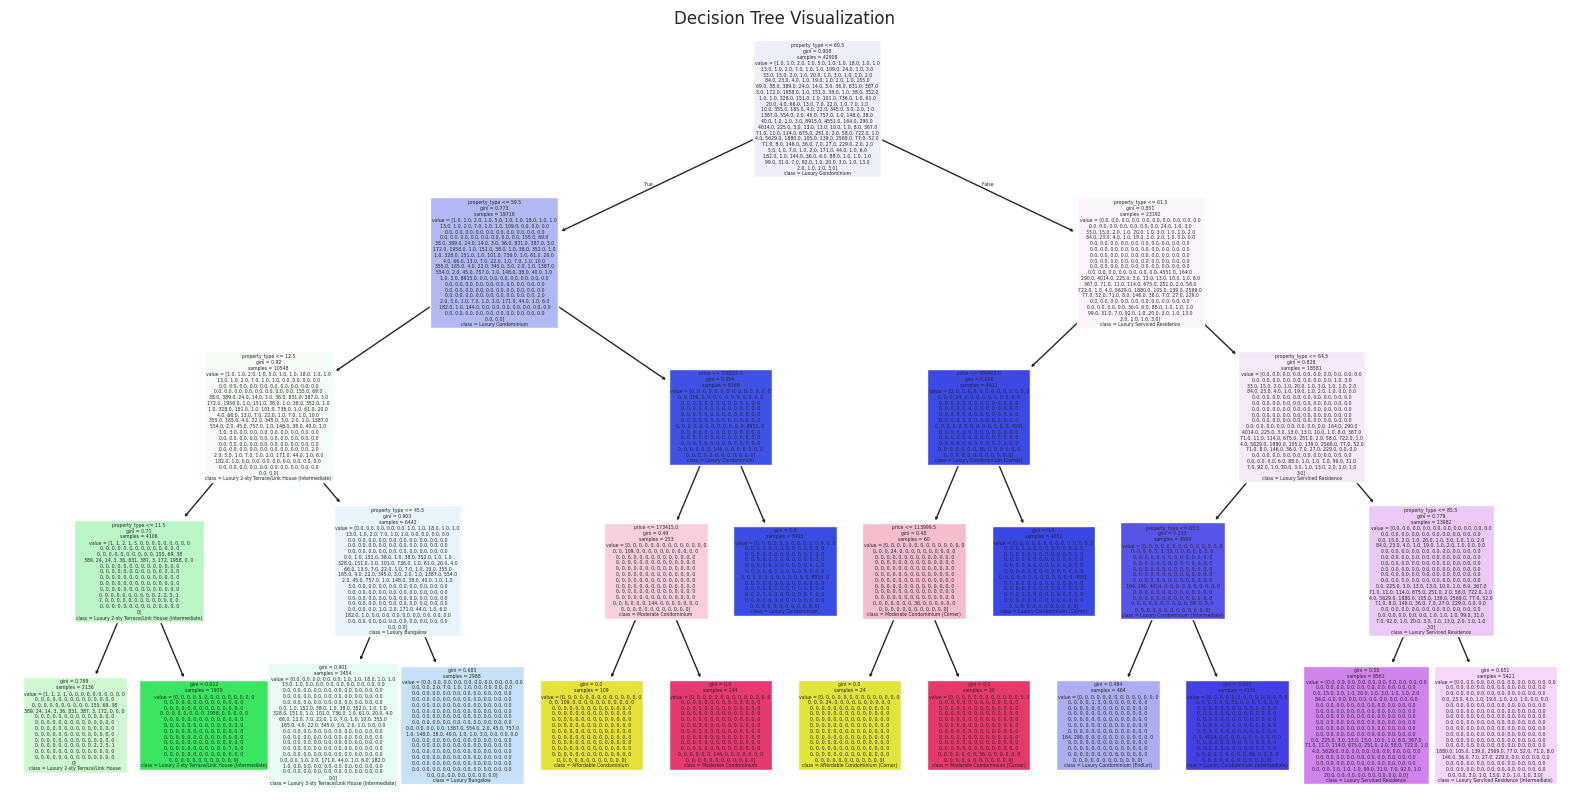


Training Random Forest...

Random Forest Performance:
                                                    precision    recall  f1-score   support

Affordable 2-sty Terrace/Link House (Intermediate)       0.00      0.00      0.00         1
Affordable 3-sty Terrace/Link House (Intermediate)       0.00      0.00      0.00         1
                              Affordable Apartment       1.00      0.20      0.33         5
               Affordable Apartment (Intermediate)       0.00      0.00      0.00         1
                               Affordable Bungalow       0.00      0.00      0.00         1
                          Affordable Bungalow Land       0.00      0.00      0.00         1
                            Affordable Condominium       0.89      1.00      0.94        25
                   Affordable Condominium (Corner)       1.00      1.00      1.00         6
             Affordable Condominium (Intermediate)       0.00      0.00      0.00         7
                        

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


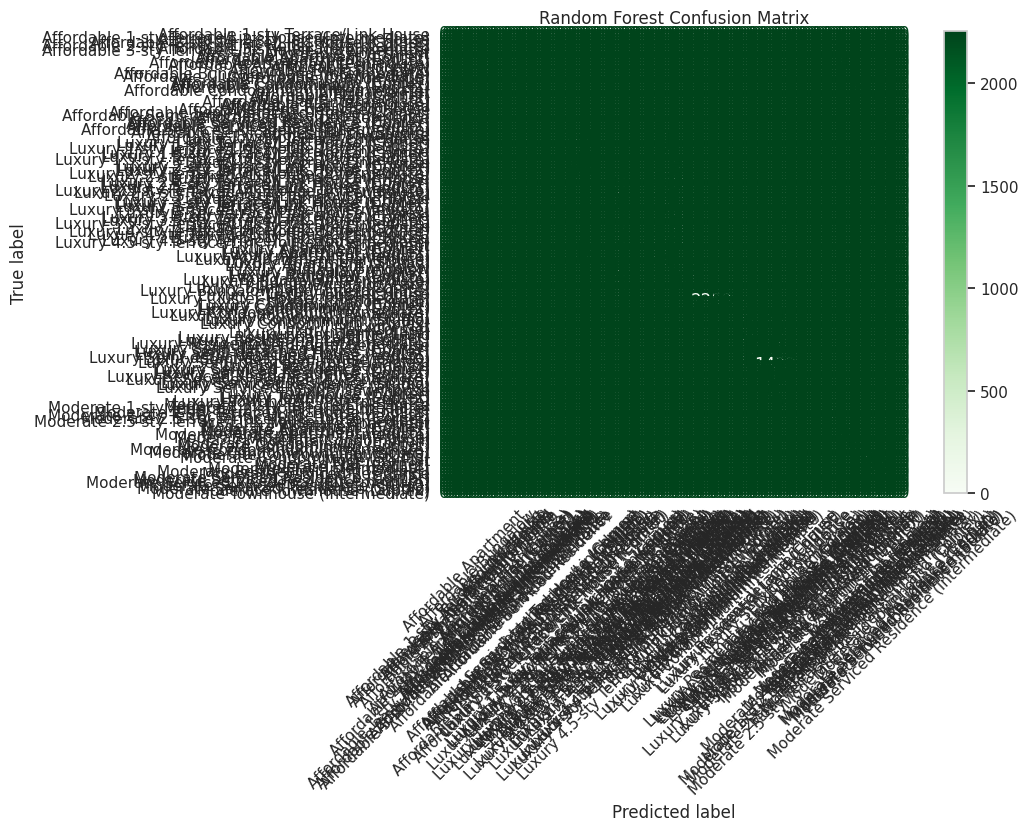


Example Predictions:
Decision Tree - Income: RM50,000, Type: House, Prediction: Luxury 2-sty Terrace/Link House
Random Forest - Income: RM50,000, Type: House, Prediction: Moderate Apartment
--------------------------------------------------
Decision Tree - Income: RM50,000, Type: Apartment, Prediction: Luxury 2-sty Terrace/Link House
Random Forest - Income: RM50,000, Type: Apartment, Prediction: Moderate Apartment
--------------------------------------------------
Decision Tree - Income: RM50,000, Type: Townhouse, Prediction: Luxury 2-sty Terrace/Link House
Random Forest - Income: RM50,000, Type: Townhouse, Prediction: Moderate Apartment
--------------------------------------------------
Decision Tree - Income: RM100,000, Type: House, Prediction: Luxury 2-sty Terrace/Link House
Random Forest - Income: RM100,000, Type: House, Prediction: Moderate Apartment
--------------------------------------------------
Decision Tree - Income: RM100,000, Type: Apartment, Prediction: Luxury 2-sty Ter

/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns

def prepare_data(income_file='final_cleaned_hh_income_state.csv',
                housing_file='final_cleaned_data_kaggle.csv'):
    # Load datasets
    income_df = pd.read_csv(income_file)
    housing_df = pd.read_csv(housing_file)

    # Clean price data
    housing_df['Price_clean'] = pd.to_numeric(housing_df['Price'].str.replace('[^\d.]', '', regex=True),
                                            errors='coerce')

    # Calculate affordability threshold (using 3x annual income as a rule of thumb)
    income_levels = income_df['income_median'].unique()

    # Create affordability categories
    def categorize_house(price, property_type):
        if pd.isna(price):
            return "Unknown"
        elif price <= 150000:
            return f"Affordable {property_type}"
        elif price <= 300000:
            return f"Moderate {property_type}"
        else:
            return f"Luxury {property_type}"

    # Create target variable
    housing_df['house_category'] = housing_df.apply(
        lambda x: categorize_house(x['Price_clean'], x['Property Type']), axis=1
    )

    # Prepare features
    features_df = pd.DataFrame({
        'price': housing_df['Price_clean'],
        'property_type': LabelEncoder().fit_transform(housing_df['Property Type'])
    })

    combined_df = pd.concat([features_df, housing_df['house_category']], axis=1)
    combined_df = combined_df.dropna()  # Now drop NaNs from the combined DataFrame

    return combined_df[['price', 'property_type']], combined_df['house_category']

def train_decision_tree(X_train, X_test, y_train, y_test):
    clf = DecisionTreeClassifier(max_depth=4, random_state=42)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    print("\nDecision Tree Performance:")
    print(classification_report(y_test, y_pred))
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")

    # Visualize Confusion Matrix
    cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
    disp.plot(cmap='Blues', xticks_rotation=45)
    plt.title("Decision Tree Confusion Matrix")
    plt.show()

    # Visualize decision tree
    plt.figure(figsize=(20, 10))
    plot_tree(clf, feature_names=['price', 'property_type'], class_names=clf.classes_, filled=True)
    plt.title("Decision Tree Visualization")
    plt.show()

    return clf

def train_random_forest(X_train, X_test, y_train, y_test):
    clf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    print("\nRandom Forest Performance:")
    print(classification_report(y_test, y_pred))
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")

    # Visualize Confusion Matrix
    cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
    disp.plot(cmap='Greens', xticks_rotation=45)
    plt.title("Random Forest Confusion Matrix")
    plt.show()

    return clf

def main():
    # Prepare data
    print("Preparing data...")
    X, y = prepare_data()
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Train and evaluate Decision Tree
    print("\nTraining Decision Tree...")
    dt_model = train_decision_tree(X_train, X_test, y_train, y_test)

    # Train and evaluate Random Forest
    print("\nTraining Random Forest...")
    rf_model = train_random_forest(X_train, X_test, y_train, y_test)

    # Example Predictions
    print("\nExample Predictions:")
    property_encoder = LabelEncoder()
    property_encoder.fit(['House', 'Apartment', 'Townhouse', 'Condo'])
    example_incomes = [50000, 100000, 150000]
    property_types = ['House', 'Apartment', 'Townhouse']

    for income in example_incomes:
        for prop_type in property_types:
            encoded_type = property_encoder.transform([prop_type])[0]
            max_price = income * 3

            # Decision Tree Prediction
            dt_prediction = dt_model.predict([[max_price, encoded_type]])[0]
            print(f"Decision Tree - Income: RM{income:,}, Type: {prop_type}, Prediction: {dt_prediction}")

            # Random Forest Prediction
            rf_prediction = rf_model.predict([[max_price, encoded_type]])[0]
            print(f"Random Forest - Income: RM{income:,}, Type: {prop_type}, Prediction: {rf_prediction}")
            print("-" * 50)

if __name__ == "__main__":
    main()
